# Notebook 02 - Isolation Forest for Credit Card Fraud Detection

## Objective
To detect fraudulent credit card transactions using the Isolation Forest algorithm.

**Dataset:** Credit Card Fraud Detection (ULB)

**Algorithm:** Isolation Forest

**Author:** Sanchita Senapati

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import IsolationForest
from sklearn.metrics import confusion_matrix, classification_report

In [13]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [2]:
df = pd.read_csv("../data/processed/creditcard_clean.csv")

In [3]:
X = df.drop("Class", axis=1)
y = df["Class"]

In [4]:
model = IsolationForest(
    contamination=y.mean(),
    random_state=42
)

In [5]:
model.fit(X)

,"contamination contamination: 'auto' or float, default='auto'The amount of contamination of the data set, i.e. the proportionof outliers in the data set. Used when fitting to define the thresholdon the scores of the samples.- If 'auto', the threshold is determined as in the original paper.- If float, the contamination should be in the range (0, 0.5]... versionchanged:: 0.22 The default value of ``contamination`` changed from 0.1 to ``'auto'``.",np.float64(0....7485630620034)
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo-randomness of the selection of the featureand split values for each branching step and each tree in the forest.Pass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"n_estimators n_estimators: int, default=100The number of base estimators in the ensemble.",100
,"max_samples max_samples: ""auto"", int or float, default=""auto""The number of samples to draw from X to train each base estimator.- If int, then draw `max_samples` samples.- If float, then draw `max_samples * X.shape[0]` samples.- If ""auto"", then `max_samples=min(256, n_samples)`.If max_samples is larger than the number of samples provided,all samples will be used for all trees (no sampling).",'auto'
,"max_features max_features: int or float, default=1.0The number of features to draw from X to train each base estimator.- If int, then draw `max_features` features.- If float, then draw `max(1, int(max_features * n_features_in_))` features.Note: using a float number less than 1.0 or integer less than number offeatures will enable feature subsampling and leads to a longer runtime.",1.0
,"bootstrap bootstrap: bool, default=FalseIf True, individual trees are fit on random subsets of the trainingdata sampled with replacement. If False, sampling without replacementis performed.",False
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel for :meth:`fit`. ``None`` means 1unless in a :obj:`joblib.parallel_backend` context. ``-1`` means usingall processors. See :term:`Glossary <n_jobs>` for more details.",None
,"verbose verbose: int, default=0Controls the verbosity of the tree building process.",0
,"warm_start warm_start: bool, default=FalseWhen set to ``True``, reuse the solution of the previous call to fitand add more estimators to the ensemble, otherwise, just fit a wholenew forest. See :term:`the Glossary <warm_start>`... versionadded:: 0.21",False
Name,Type,Value
estimator_ estimator_: :class:`~sklearn.tree.ExtraTreeRegressor` instanceThe child estimator template used to create the collection offitted sub-estimators... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,ExtraTreeRegressor,ExtraTreeRegr...ndom_state=42)


In [6]:
predictions = model.predict(X)

predictions[:10]

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1])

In [7]:
predictions = np.where(predictions == 1, 0, 1)

predictions[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0])

In [8]:
cm = confusion_matrix(y, predictions)

print(cm)

[[283949    366]
 [   366    126]]


In [9]:
cm = confusion_matrix(y, predictions)

print(cm)

[[283949    366]
 [   366    126]]


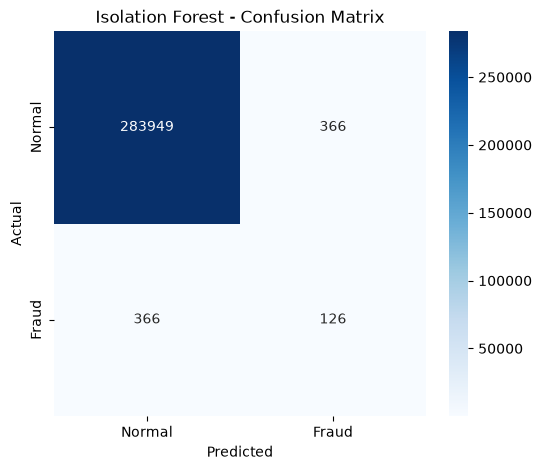

In [10]:
import seaborn as sns

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Normal", "Fraud"],
    yticklabels=["Normal", "Fraud"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Isolation Forest - Confusion Matrix")

plt.show()

In [11]:
TN, FP, FN, TP = cm.ravel()

false_positive_rate = FP / (FP + TN)

print("False Positive Rate:", false_positive_rate)

False Positive Rate: 0.001287304574151909


In [14]:
accuracy = accuracy_score(y, predictions)
precision = precision_score(y, predictions)
recall = recall_score(y, predictions)
f1 = f1_score(y, predictions)

print("Isolation Forest Results")
print("-----------------------")
print(f"Accuracy:            {accuracy:.4f}")
print(f"Precision:           {precision:.4f}")
print(f"Recall:              {recall:.4f}")
print(f"F1-Score:            {f1:.4f}")
print(f"False Positive Rate: {false_positive_rate:.6f}")

Isolation Forest Results
-----------------------
Accuracy:            0.9974
Precision:           0.2561
Recall:              0.2561
F1-Score:            0.2561
False Positive Rate: 0.001287


In [15]:
print("\nDetailed Classification Report:")
print(classification_report(
    y,
    predictions,
    target_names=["Normal", "Fraud"]
))


Detailed Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00    284315
       Fraud       0.26      0.26      0.26       492

    accuracy                           1.00    284807
   macro avg       0.63      0.63      0.63    284807
weighted avg       1.00      1.00      1.00    284807



In [16]:
if_predictions = predictions.copy()

print("Isolation Forest predictions saved.")
print("Isolation Forest anomalies:", if_predictions.sum())

Isolation Forest predictions saved.
Isolation Forest anomalies: 492


In [18]:
# Load the saved Autoencoder, scaler, and threshold

import tensorflow as tf
import joblib
import json

autoencoder = tf.keras.models.load_model(
    "../models/autoencoder.keras"
)

scaler = joblib.load(
    "../models/scaler.pkl"
)

with open("../models/threshold.json", "r") as f:
    threshold = json.load(f)["threshold"]

print("Autoencoder loaded.")
print("Threshold:", threshold)
print("Model input shape:", autoencoder.input_shape)

Autoencoder loaded.
Threshold: 4.7944
Model input shape: (None, 30)
